# CatBoost MultiClass: 18 tổ hợp môn lớp 10

Notebook bàn giao được **tái sử dụng và cập nhật** từ `experiments/catboost/catboost_multiclass_18_to_hop.ipynb`. Phiên bản này đọc kết quả đã lưu; không fit mô hình và không chấm lại test cũ. Dữ liệu mô phỏng hoặc nguồn nhãn chưa xác minh. Xem `bao_cao_catboost.md` trong cùng thư mục.

## 1. Cấu hình và nguồn

A1: CatBoost MultiClass F4, 70 đặc trưng số, 331 cây, `auto_class_weights=None`. A4: trung bình xác suất A1 và Logistic Regression 50/50. Tập dev gồm 8.500 học sinh, 5 fold × 3 seed (42, 101, 202); test cũ 1.500 học sinh chỉ **đọc bảng kết quả đã lưu**. Ma trận bên dưới dùng seed 42 OOF dev để mỗi học sinh xuất hiện đúng một lần. Hàng là tổ hợp thật, cột là tổ hợp được dự báo.

In [1]:
from pathlib import Path
import json, base64, zlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
from IPython.display import display

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / 'experiments/catboost/combo_selection/final_metrics.csv').exists()), None)
if ROOT is None:
    raise FileNotFoundError('Chạy notebook từ repo hoặc một thư mục con của repo')
CAT = ROOT / 'experiments/catboost'
COMBO = CAT / 'combo_selection'
EXACT = CAT / 'exact_improvement'
REVIEW = CAT / 'final_review'
config = json.loads((EXACT / 'run_config.json').read_text(encoding='utf-8'))
classes = config['class_codes']
subjects = config['label_names']
assert len(classes) == 18 and config['feature_set'] == 'F4' and config['catboost_params']['iterations'] == 331
print('Đã nạp cấu hình: F4, 18 tổ hợp, 331 cây; seed =', config['seed_list'])

Đã nạp cấu hình: F4, 18 tổ hợp, 331 cây; seed = [42, 101, 202]


## 2. Chỉ số và bảng kết quả

- **Exact-match:** đúng nguyên bộ bốn môn, tức đúng một trong 18 tổ hợp.
- **Top-3:** tổ hợp thật nằm trong ba tổ hợp xác suất cao nhất, không phải ba môn.
- **Precision@4:** trung bình tỷ lệ môn đúng trong bốn môn được chọn.
- **LogLoss18:** mất mát xác suất trên 18 tổ hợp; thấp hơn là tốt hơn.
- **F1 macro18 / recall macro18:** trung bình đều trên 18 tổ hợp, làm lộ việc bỏ sót lớp hiếm.

Baseline tổ hợp phổ biến nhất chọn một tổ hợp cố định; phân bố tần suất train của nó dùng để xếp Top-3. Baseline bốn môn phổ biến ghép nhãn riêng lẻ, nên LogLoss chín nhãn không so với LogLoss18.

In [2]:
dev = pd.read_csv(EXACT / 'summary.csv').set_index('candidate')
test = pd.read_csv(COMBO / 'final_metrics.csv').set_index('model')
ci = pd.read_csv(COMBO / 'test_ci.csv').set_index('metric')
paired_summary = json.loads((REVIEW / 'paired_summary.json').read_text(encoding='utf-8'))
print('Dev OOF: trung bình 15 fold, cùng 8.500 học sinh (không phải 25.500 học sinh độc lập)')
dev_show = dev.loc[['A1','A2','A4'], ['exact_mean','exact_sd','top3_mean','precision_at_4_mean','log_loss_mean','f1_macro_mean','recall_macro_mean','wins_baseline']].round(4)
display(dev_show)
print('Test cũ: chỉ A1 và baseline tổ hợp; không có kết quả test A4')
display(test.loc[['catboost_direct','popular_combo_prior'], ['exact','top3','precision_at_4','log_loss','f1_macro','recall_macro']].round(4))
print('CI95 của hiệu A1 - baseline trên cùng 1.500 test (đã lưu):')
display(ci[['effect_mean','ci95_low','ci95_high']].round(4))
print(f"A4 - A1 trên dev: {paired_summary['delta']*100:+.4f} điểm %, CI95 [{paired_summary['ci95_low']*100:+.4f}; {paired_summary['ci95_high']*100:+.4f}] điểm %; thăm dò sau chọn A4.")

Dev OOF: trung bình 15 fold, cùng 8.500 học sinh (không phải 25.500 học sinh độc lập)


,exact_mean,exact_sd,top3_mean,precision_at_4_mean,log_loss_mean,f1_macro_mean,recall_macro_mean,wins_baseline
candidate,,,,,,,,
A1,0.2740,0.0033,0.5791,0.6588,2.2039,0.0424,0.0649,15
A2,0.2761,0.0087,0.5774,0.6612,2.2022,0.0470,0.0672,14
A4,0.2776,0.0053,0.5807,0.6611,2.1999,0.0456,0.0667,15


Test cũ: chỉ A1 và baseline tổ hợp; không có kết quả test A4


,exact,top3,precision_at_4,log_loss,f1_macro,recall_macro
model,,,,,,
catboost_direct,0.2573,0.588,0.6467,2.2141,0.0369,0.0595
popular_combo_prior,0.2613,0.572,0.6193,2.2378,0.0230,0.0556


CI95 của hiệu A1 - baseline trên cùng 1.500 test (đã lưu):


,effect_mean,ci95_low,ci95_high
metric,,,
exact,-0.0040,-0.0173,0.0100
top3,0.0160,0.0040,0.0280
log_loss,-0.0237,-0.0359,-0.0120
precision_at_4,0.0273,0.0172,0.0372


A4 - A1 trên dev: +0.3569 điểm %, CI95 [+0.0391; +0.6589] điểm %; thăm dò sau chọn A4.


## 3. Ma trận nhầm lẫn A1 và A4 trên cùng OOF dev

Dùng `final_review/paired_oof.csv`; mỗi hàng có nhãn thật và hai dự báo ngoài mẫu cùng ID, seed, fold. Cell chỉ dùng seed 42, đúng 8.500 học sinh, cùng thứ tự 18 lớp trong cấu hình. Màu đậm ở đường chéo nghĩa là đoán đúng tổ hợp. Ma trận không phải kết quả test.

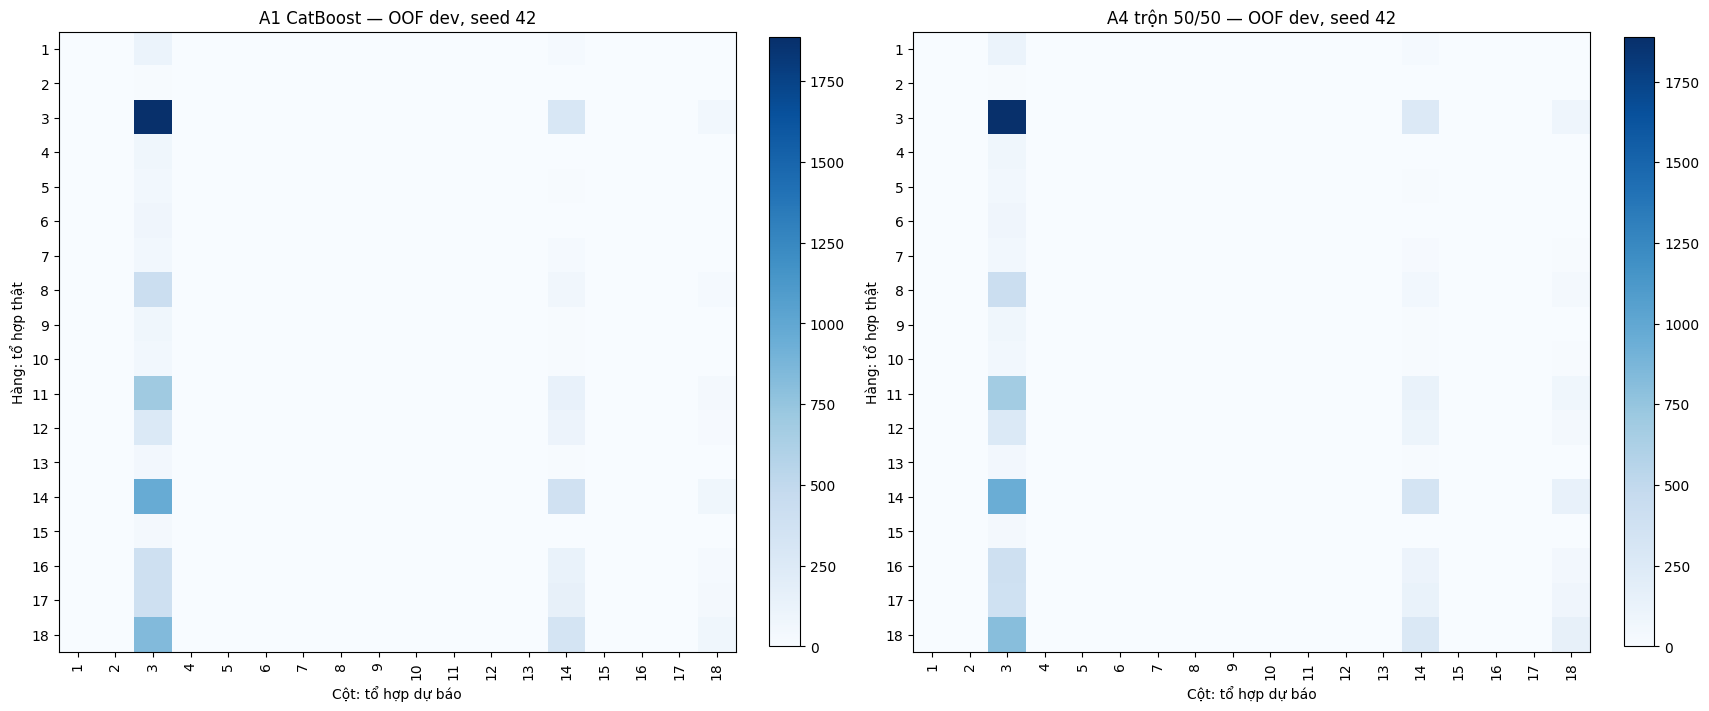

Hai ma trận cùng 8.500 hồ sơ; mã 1–18 theo thứ tự trong run_config.json.


In [3]:
oof = pd.read_csv(REVIEW / 'paired_oof.csv', dtype={'id':str, 'truth':str, 'a1':str, 'a4':str})
assert len(oof) == 25500 and not oof.duplicated(['id','seed']).any()
assert set(oof['truth']) <= set(classes) and set(oof['a1']) <= set(classes) and set(oof['a4']) <= set(classes)
seed42 = oof[oof.seed == 42].copy()
assert len(seed42) == 8500 and seed42.id.is_unique
assert (seed42.truth == seed42.a1).mean() == seed42.a1_correct.mean()
fig, axes = plt.subplots(1, 2, figsize=(17, 7), constrained_layout=True)
for ax, name, title in zip(axes, ['a1','a4'], ['A1 CatBoost','A4 trộn 50/50']):
    cm = confusion_matrix(seed42.truth, seed42[name], labels=classes)
    assert cm.shape == (18,18) and cm.sum() == 8500
    im = ax.imshow(cm, cmap='Blues', aspect='auto')
    ax.set_title(f'{title} — OOF dev, seed 42')
    ax.set_xlabel('Cột: tổ hợp dự báo')
    ax.set_ylabel('Hàng: tổ hợp thật')
    ax.set_xticks(range(18), range(1,19), rotation=90)
    ax.set_yticks(range(18), range(1,19))
    fig.colorbar(im, ax=ax, fraction=0.045)
plt.show()
print('Hai ma trận cùng 8.500 hồ sơ; mã 1–18 theo thứ tự trong run_config.json.')

## 4. Bảng theo từng tổ hợp

`Số mẫu thật` là support; `Số lượt dự báo` là số lần mô hình chọn tổ hợp; `Số ca đúng` là phần giao của hai nhóm; recall = số ca đúng / số mẫu thật. Bảng dưới tiếp tục dùng seed 42 OOF dev, cùng 8.500 học sinh cho A1 và A4. Tổ hợp có recall 0 là nhóm bị bỏ sót.

In [4]:
rows=[]
for name in ['a1','a4']:
    for c in classes:
        real = seed42.truth.eq(c)
        pred = seed42[name].eq(c)
        n = int(real.sum()); chosen = int(pred.sum()); correct = int((real & pred).sum())
        rows.append({'mô hình':name.upper(), 'mã':c,
                     'môn':'+'.join(subjects[i] for i,v in enumerate(c) if v == '1'),
                     'số mẫu thật':n, 'số lượt dự báo':chosen, 'số ca đúng':correct,
                     'recall':correct/n if n else np.nan})
per_combo = pd.DataFrame(rows)
display(per_combo.round({'recall':4}).to_string(index=False))
print('Tổng ca đúng seed 42:', per_combo.groupby('mô hình')['số ca đúng'].sum().to_dict())

'mô hình        mã                                môn  số mẫu thật  số lượt dự báo  số ca đúng  recall\n     A1 000101101  dia_li+tin_hoc+cong_nghe+mi_thuat          145               0           0  0.0000\n     A1 000101110   dia_li+tin_hoc+cong_nghe+am_nhac           17               0           0  0.0000\n     A1 000111100    dia_li+gdktpl+tin_hoc+cong_nghe         2226            6442        1886  0.8473\n     A1 001111000     sinh_hoc+dia_li+gdktpl+tin_hoc           82               0           0  0.0000\n     A1 010101100   hoa_hoc+dia_li+tin_hoc+cong_nghe           71               0           0  0.0000\n     A1 010111000      hoa_hoc+dia_li+gdktpl+tin_hoc           80               0           0  0.0000\n     A1 011001100 hoa_hoc+sinh_hoc+tin_hoc+cong_nghe           79               0           0  0.0000\n     A1 011110000     hoa_hoc+sinh_hoc+dia_li+gdktpl          511               0           0  0.0000\n     A1 100011100    vat_li+gdktpl+tin_hoc+cong_nghe           85       

Tổng ca đúng seed 42: {'A1': 2326, 'A4': 2365}


## 5. Minh họa Top-3 bằng một dự đoán OOF dev

Lấy hàng đầu tiên của fold 1, seed 42 trong cache xác suất A1. Thứ tự hàng được kiểm tra với `paired_oof.csv`; chỉ hiển thị nhãn và xác suất, **không hiển thị ID học sinh**. Đây là minh họa từ dự đoán đã lưu, không phải suy luận mới.

In [5]:
fold_cache = pd.read_csv(EXACT / 'per_fold.csv', dtype={'hash':str})
r = fold_cache[(fold_cache.candidate == 'A1') & (fold_cache.seed == 42) & (fold_cache.fold == 1)].iloc[0]
raw = zlib.decompress(base64.b64decode(r.probability_zlib_b64))
p = np.frombuffer(raw, dtype=np.float64).reshape(int(r.n_val), len(classes))
pair = seed42[seed42.fold == 1].iloc[0]
assert len(seed42[seed42.fold == 1]) == len(p) and classes[p[0].argmax()] == pair.a1
order = np.argsort(-p[0])[:3]
example = pd.DataFrame({'hạng':[1,2,3], 'mã tổ hợp':[classes[i] for i in order],
                        'bốn môn':[' + '.join(subjects[j] for j,v in enumerate(classes[i]) if v=='1') for i in order],
                        'xác suất A1':[p[0,i] for i in order]})
display(example.round({'xác suất A1':4}))
print('Tổ hợp thật:', pair.truth, '| Có trong Top-3:', pair.truth in set(example['mã tổ hợp']))

,hạng,mã tổ hợp,bốn môn,xác suất A1
0,1,000111100,dia_li + gdktpl + tin_hoc + cong_nghe,0.2023
1,2,110001100,vat_li + hoa_hoc + tin_hoc + cong_nghe,0.1949
2,3,111001000,vat_li + hoa_hoc + sinh_hoc + tin_hoc,0.1731


Tổ hợp thật: 111001000 | Có trong Top-3: True


## 6. Hiệu chuẩn theo nhóm xác suất và quyết định

Mỗi nhóm có 1.700 học sinh dev. `mean_max_probability` là xác suất cao nhất trung bình; `exact_rate` là tỷ lệ đúng nguyên tổ hợp. Độ khớp theo nhóm không cho biết tổ hợp có phù hợp cá nhân hay không.

In [6]:
cal = pd.read_csv(EXACT / 'calibration.csv')
display(cal[cal.candidate.isin(['A1','A4'])][['candidate','quantile_group','n','mean_max_probability','exact_rate']].round(4))
print('Kết luận test cũ: CHƯA ĐẠT cho Exact. A1 có tín hiệu Top-3 trong bản thử nghiệm. A4 cần tập độc lập chưa dùng để xác nhận.')

,candidate,quantile_group,n,mean_max_probability,exact_rate
0,A1,1,1700,0.2035,0.2047
1,A1,2,1700,0.2272,0.2206
2,A1,3,1700,0.2584,0.2700
3,A1,4,1700,0.3078,0.3041
4,A1,5,1700,0.3776,0.3788
15,A4,1,1700,0.2043,0.2135
16,A4,2,1700,0.2295,0.2182
17,A4,3,1700,0.2592,0.2553
18,A4,4,1700,0.3073,0.3153
19,A4,5,1700,0.3860,0.3906


Kết luận test cũ: CHƯA ĐẠT cho Exact. A1 có tín hiệu Top-3 trong bản thử nghiệm. A4 cần tập độc lập chưa dùng để xác nhận.


## 7. Tái lập và giới hạn

Chạy từ gốc repo: `python -m nbconvert --to notebook --execute --inplace deliverables/catboost_to_hop/catboost_multiclass_18_to_hop.ipynb`. Nguồn chính: `experiments/catboost/combo_selection/`, `weight_tuning/`, `exact_improvement/`, `final_review/`. Notebook đọc các kết quả đã lưu; không huấn luyện lại và không đánh giá lại test. Dữ liệu mô phỏng; chưa có thí nghiệm định lượng về nhiễu điểm/nhãn hoặc kiểm tra trên dữ liệu độc lập.